<a href="https://colab.research.google.com/github/manchinillaanvesh257-bot/.py/blob/main/Copy_of_Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA CLEANING AND EXPLORATORY DATA ANALYSIS

First 5 Rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Dataset Shape:
(891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embar

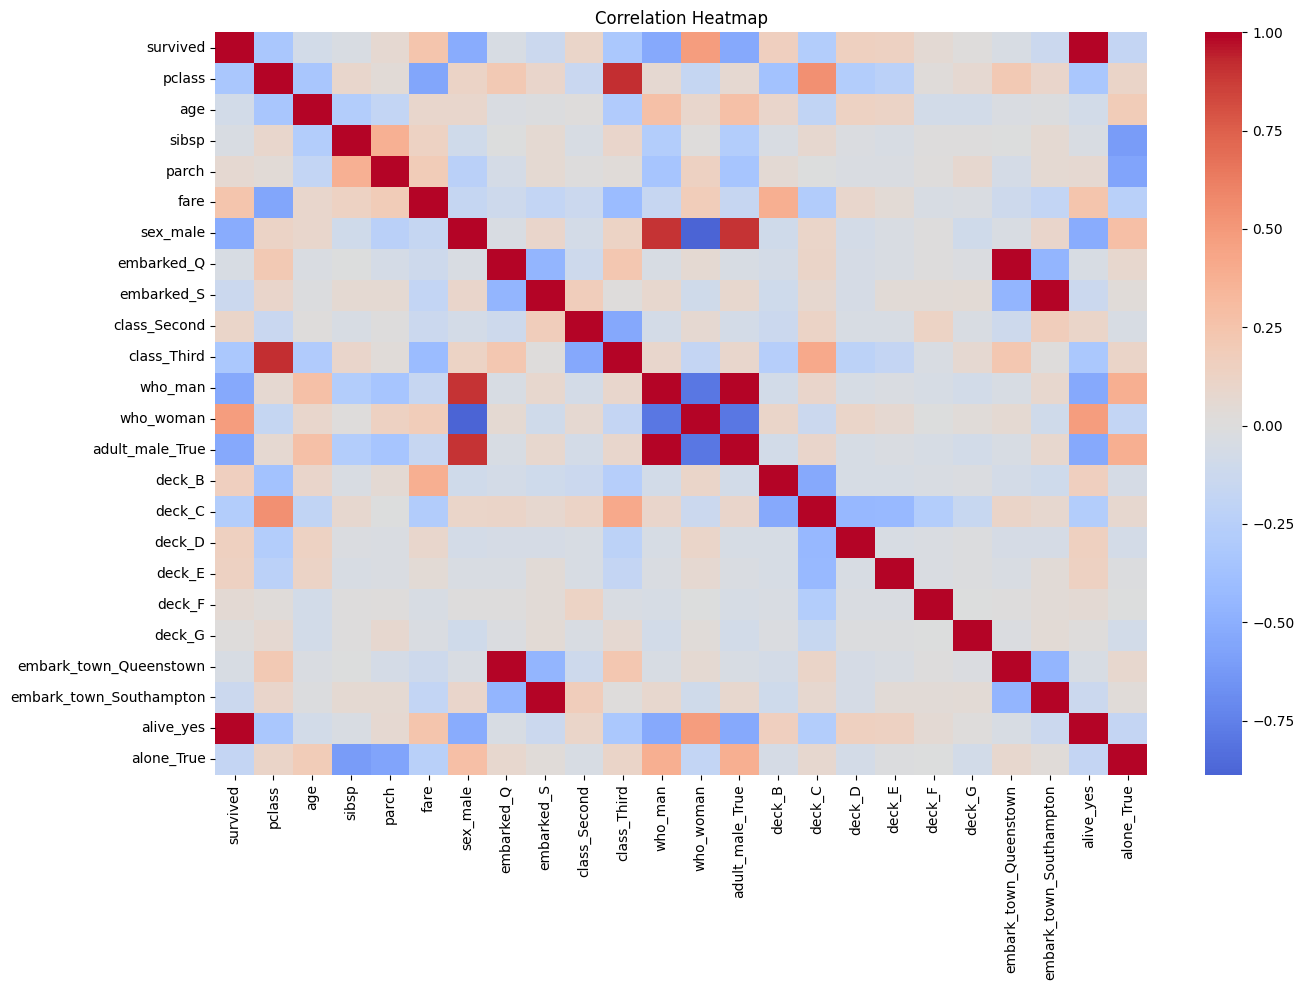

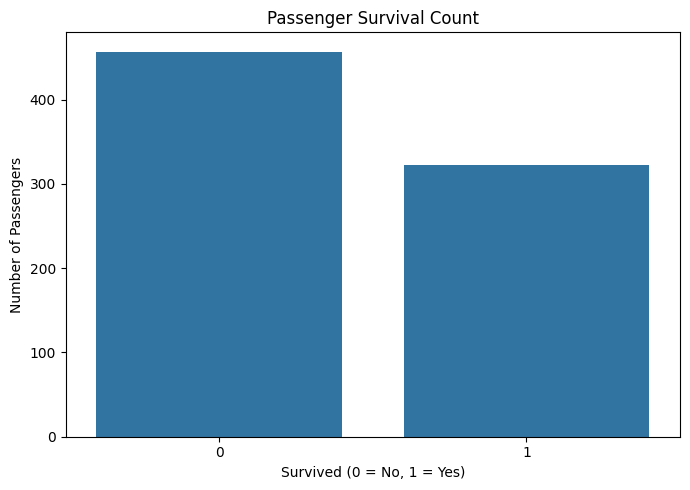

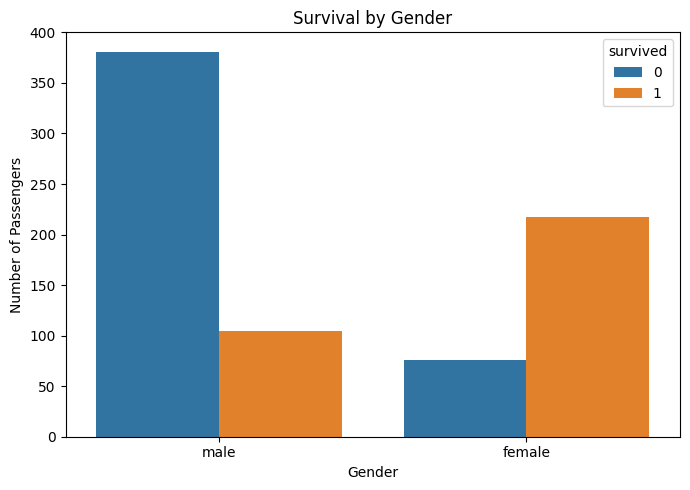

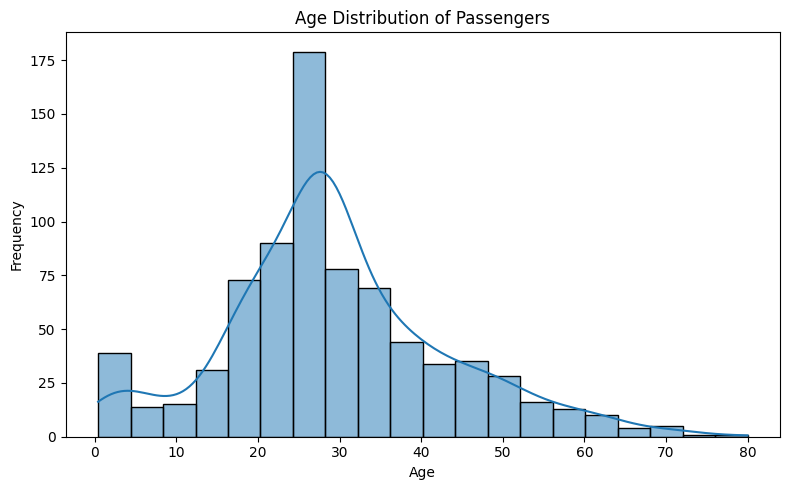

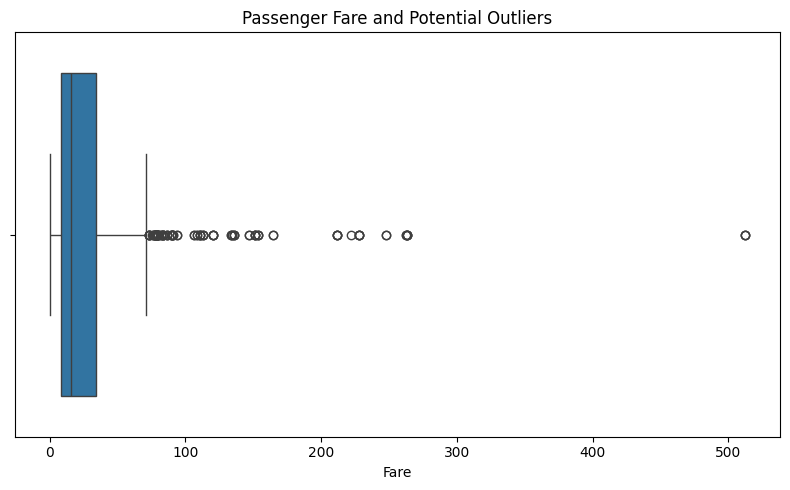

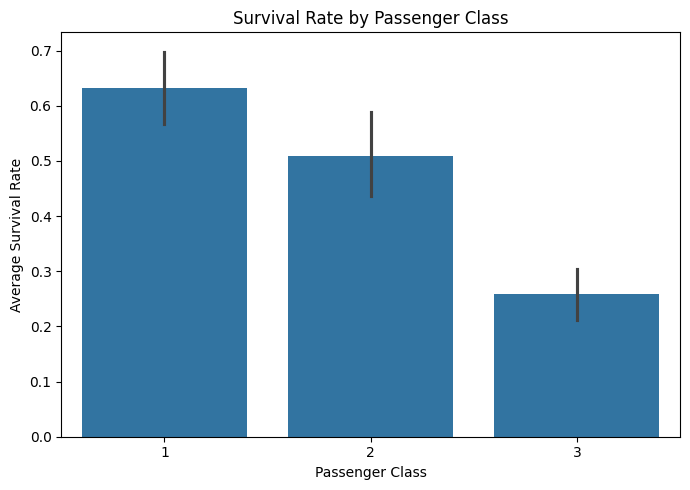


IMPORTANT FEATURES

Features Ranked by Absolute Correlation:
alive_yes          1.000000
who_man            0.528808
adult_male_True    0.528808
sex_male           0.516018
who_woman          0.481118
pclass             0.331448
class_Third        0.324285
deck_C             0.275348
fare               0.247000
alone_True         0.175088
Name: survived, dtype: float64

Cleaned dataset saved as titanic_cleaned.csv
Encoded dataset saved as titanic_encoded.csv
Scaled dataset saved as titanic_scaled.csv

DATA CLEANING AND EDA COMPLETED SUCCESSFULLY!


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder

# ------------------------------------------
# 1. LOAD AND UNDERSTAND THE DATASET
# ------------------------------------------

print("DATA CLEANING AND EXPLORATORY DATA ANALYSIS")

df = sns.load_dataset("titanic")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

# ------------------------------------------
# 2. HANDLE MISSING VALUES
# ------------------------------------------

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Fill numerical missing values with the median
numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Fill categorical missing values with the mode
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for column in categorical_columns:
    mode_values = df[column].mode()

    if not mode_values.empty:
        df[column] = df[column].fillna(mode_values.iloc[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

# ------------------------------------------
# 3. REMOVE DUPLICATE RECORDS
# ------------------------------------------

print("\nDuplicate Records Before Removal:")
print(df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset Shape After Removing Duplicates:")
print(df.shape)

# ------------------------------------------
# 4. IDENTIFY POTENTIAL OUTLIERS
# ------------------------------------------

print("\nOUTLIER DETECTION USING IQR")

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

# ------------------------------------------
# 5. ENCODE CATEGORICAL VARIABLES
# ------------------------------------------

df_encoded = df.copy()

categorical_columns = df_encoded.select_dtypes(
    include=["object", "category", "bool"]
).columns

df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("\nDataset After Categorical Encoding:")
print(df_encoded.head())

# ------------------------------------------
# 6. APPLY FEATURE SCALING
# ------------------------------------------

df_scaled = df_encoded.copy()

numeric_columns = df_scaled.select_dtypes(
    include=np.number
).columns

scaler = StandardScaler()

df_scaled[numeric_columns] = scaler.fit_transform(
    df_scaled[numeric_columns]
)

print("\nDataset After Feature Scaling:")
print(df_scaled.head())

# ------------------------------------------
# 7. ANALYZE RELATIONSHIPS BETWEEN VARIABLES
# ------------------------------------------

print("\nSURVIVAL ANALYSIS")

if "survived" in df.columns:

    print("\nSurvival Count:")
    print(df["survived"].value_counts())

    print("\nSurvival Rate by Gender:")
    print(df.groupby("sex", observed=True)["survived"].mean())

    print("\nSurvival Rate by Passenger Class:")
    print(df.groupby("pclass")["survived"].mean())

# ------------------------------------------
# 8. CORRELATION ANALYSIS
# ------------------------------------------

correlation = df_encoded.corr(numeric_only=True)

print("\nCorrelation with Survival:")

if "survived" in correlation.columns:
    print(
        correlation["survived"]
        .sort_values(ascending=False)
    )

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 9. CREATE MEANINGFUL CHARTS AND GRAPHS
# ------------------------------------------

# Chart 1: Survival Count
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

# Chart 2: Survival by Gender
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

# Chart 3: Age Distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Chart 4: Fare Distribution and Potential Outliers
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fare")

plt.title("Passenger Fare and Potential Outliers")
plt.xlabel("Fare")

plt.tight_layout()
plt.show()

# Chart 5: Survival by Passenger Class
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="pclass",
    y="survived"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Survival Rate")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 10. IDENTIFY IMPORTANT FEATURES
# ------------------------------------------

print("\nIMPORTANT FEATURES")

if "survived" in correlation.columns:

    feature_importance = (
        correlation["survived"]
        .drop("survived")
        .abs()
        .sort_values(ascending=False)
    )

    print("\nFeatures Ranked by Absolute Correlation:")
    print(feature_importance.head(10))

# ------------------------------------------
# SAVE CLEANED DATASET
# ------------------------------------------

df.to_csv("titanic_cleaned.csv", index=False)

df_encoded.to_csv("titanic_encoded.csv", index=False)

df_scaled.to_csv("titanic_scaled.csv", index=False)

print("\nCleaned dataset saved as titanic_cleaned.csv")
print("Encoded dataset saved as titanic_encoded.csv")
print("Scaled dataset saved as titanic_scaled.csv")

print("\nDATA CLEANING AND EDA COMPLETED SUCCESSFULLY!")